Fitting 5 folds for each of 18 candidates, totalling 90 fits
--- Best SVM Hyperparameters ---
{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV accuracy: 0.6726

--- SVM Classification Results ---
Accuracy: 0.7136
Precision: 0.7162
Recall   : 0.7136
F1 Score : 0.7126

Classification Report:
              precision    recall  f1-score   support

         cel       0.82      0.76      0.79        95
         cla       0.65      0.67      0.66        96
         flu       0.63      0.69      0.66        85
         gac       0.74      0.74      0.74       151
         gel       0.64      0.70      0.67       139
         org       0.79      0.80      0.80       145
         pia       0.71      0.73      0.72       142
         sax       0.70      0.50      0.58       114
         tru       0.79      0.74      0.76       119
         vio       0.73      0.68      0.70       109
         voi       0.68      0.79      0.73       146

    accuracy                           0.71      1341
 

<Figure size 1000x800 with 0 Axes>

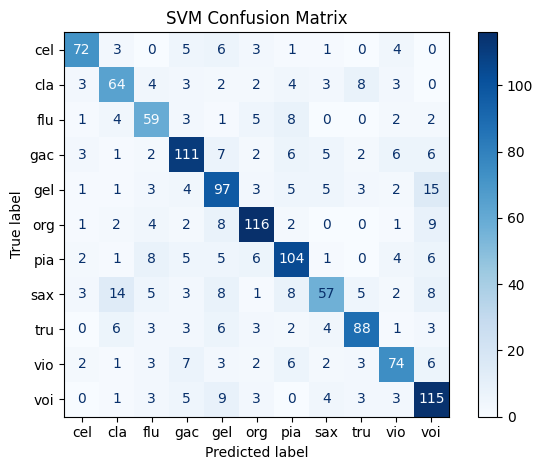

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn import svm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Load the dataset
data = pd.read_csv(r"C:\Users\LENOVO\Documents\ML Project(Instrument Classifier)\Music Dataset.csv")
X = data.drop("Instrument", axis=1)
y = data["Instrument"]

# 2. Split the data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. Search hyperparameters for the best SVM model
svc = svm.SVC()
param_grid = {
    "kernel": ["linear", "rbf", "poly"],
    "C": [0.1, 1, 10],
    "gamma": ["scale", "auto"]
}
grid = GridSearchCV(svc, param_grid, cv=5, scoring="accuracy", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("--- Best SVM Hyperparameters ---")
print(grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}\n")

# 4. Evaluate the selected model on the test set
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
conf_matrix = confusion_matrix(y_test, y_pred)

print("--- SVM Classification Results ---")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 5. Display confusion matrix
plt.figure(figsize=(10, 8))
ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=best_model.classes_).plot(cmap='Blues')
plt.title('SVM Confusion Matrix')
plt.tight_layout()
plt.show()